# Sokoni Retail Data: Cleaning & Visualisation
Run the cells **one at a time** (Shift+Enter) and read each output before moving on.

Place `sokoni_retail_data.csv` in the same folder as this notebook.

## Step 1: Load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

df = pd.read_csv('sokoni_retail_data.csv')
raw = df.copy()          # keep an untouched copy to compare against later
df.head()

,transaction_id,date,branch,branch_manager,product_category,product_name,quantity,unit_price,total_sales,cost_price,profit,payment_method,customer_satisfaction,returned,staff_count,month,month_num
0,TXN1000,2024-04-12,Eastleigh,David Kimani,Clothing,Jacket,1,4500,4500.0,3000,1500.0,M-Pesa,2.0,No,15,April,4
1,TXN1001,2024-04-09,Karen,Cynthia Mwangi,Electronics,Earphones,2,2500,5000.0,1500,2000.0,M-Pesa,3.0,No,10,April,4
2,TXN1002,2024-01-22,Thika Road,Esther Njeri,Electronics,Phone Charger,3,1500,4500.0,900,1800.0,Card,3.0,No,11,January,1
3,TXN1003,2024-07-08,Karen,Cynthia Mwangi,Clothing,Sneakers,1,3500,3500.0,2200,1300.0,M-Pesa,3.0,Yes,8,July,7
4,TXN1004,2024-03-29,Eastleigh,David Kimani,Groceries,Cooking Oil 1L,9,350,3150.0,250,900.0,M-Pesa,3.0,No,16,March,3


## Step 2: Inspect the structure
We check size, data types and what is missing before changing anything.

In [2]:
print('Shape:', df.shape)
df.info()

Shape: (1200, 17)
<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   transaction_id         1200 non-null   str    
 1   date                   1200 non-null   str    
 2   branch                 1200 non-null   str    
 3   branch_manager         1200 non-null   str    
 4   product_category       1200 non-null   str    
 5   product_name           1200 non-null   str    
 6   quantity               1200 non-null   int64  
 7   unit_price             1200 non-null   int64  
 8   total_sales            1194 non-null   float64
 9   cost_price             1200 non-null   int64  
 10  profit                 1188 non-null   float64
 11  payment_method         1200 non-null   str    
 12  customer_satisfaction  1081 non-null   float64
 13  returned               1200 non-null   str    
 14  staff_count            1200 non-null   int64  
 1

In [3]:
missing = df.isna().sum()
missing[missing > 0].to_frame('missing').assign(pct=lambda x: (x.missing / len(df) * 100).round(1))

,missing,pct
total_sales,6,0.5
profit,12,1.0
customer_satisfaction,119,9.9


**Findings:** `total_sales` (6), `profit` (12) and `customer_satisfaction` (119) have gaps. `date` is stored as text.

## Step 3: Standardise column names and text

In [4]:
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

text_cols = df.select_dtypes(include=['object', 'string']).columns
for c in text_cols:
    df[c] = df[c].str.strip()

# check categorical columns for typos / inconsistent labels
for c in ['branch', 'product_category', 'product_name', 'payment_method', 'returned']:
    print(c, '->', sorted(df[c].unique()))

branch -> ['CBD', 'Eastleigh', 'Karen', 'Thika Road', 'Westlands']
product_category -> ['Clothing', 'Electronics', 'Groceries', 'Home & Living']
product_name -> ['Bedsheet Set', 'Bluetooth Speaker', 'Cooking Oil 1L', 'Cooking Pot', 'Earphones', 'Jacket', 'Jeans', 'Maize Flour 2kg', 'Phone Charger', 'Power Bank', 'Rice 2kg', 'Sneakers', 'Sugar 1kg', 'T-Shirt', 'Table Lamp', 'Wall Clock']
payment_method -> ['Card', 'Cash', 'M-Pesa']
returned -> ['No', 'Yes']


All labels are already consistent here, but this step is the standard safety check.

## Step 4: Check for duplicates

In [5]:
print('Fully duplicated rows :', df.duplicated().sum())
print('Duplicated transaction IDs:', df['transaction_id'].duplicated().sum())
df = df.drop_duplicates(subset='transaction_id')

Fully duplicated rows : 0
Duplicated transaction IDs: 0


## Step 5: Fix data types

In [6]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')
print('Unparseable dates:', df['date'].isna().sum())

df['returned'] = df['returned'].map({'Yes': True, 'No': False})

for c in ['branch', 'branch_manager', 'product_category', 'product_name', 'payment_method']:
    df[c] = df[c].astype('category')

df.dtypes

Unparseable dates: 0


transaction_id                      str
date                     datetime64[us]
branch                         category
branch_manager                 category
product_category               category
product_name                   category
quantity                          int64
unit_price                        int64
total_sales                     float64
cost_price                        int64
profit                          float64
payment_method                 category
customer_satisfaction           float64
returned                           bool
staff_count                       int64
month                               str
month_num                         int64
dtype: object

## Step 6: Validate the date-derived columns
`month` and `month_num` duplicate information already in `date`. First confirm they agree, then drop them.

In [7]:
print('month_num mismatches:', (df['date'].dt.month != df['month_num']).sum())
print('month name mismatches:', (df['date'].dt.month_name() != df['month']).sum())

df = df.drop(columns=['month', 'month_num'])
df['month'] = df['date'].dt.to_period('M').dt.to_timestamp()   # first day of month, good for plotting
df['month_name'] = df['date'].dt.month_name()

month_num mismatches: 0
month name mismatches: 0


## Step 7: Fix missing `total_sales` and `profit`
These are **calculable**, so we recompute them instead of guessing. First prove the formulas hold on the rows that are not missing.

In [8]:
ok_sales  = df['total_sales'].notna()
ok_profit = df['profit'].notna()

print('total_sales = quantity * unit_price holds on all complete rows:',
      np.allclose(df.loc[ok_sales, 'total_sales'], (df['quantity'] * df['unit_price'])[ok_sales]))
print('profit = quantity * (unit_price - cost_price) holds on all complete rows:',
      np.allclose(df.loc[ok_profit, 'profit'], (df['quantity'] * (df['unit_price'] - df['cost_price']))[ok_profit]))

total_sales = quantity * unit_price holds on all complete rows: True
profit = quantity * (unit_price - cost_price) holds on all complete rows: True


In [9]:
df['total_sales'] = df['total_sales'].fillna(df['quantity'] * df['unit_price'])
df['profit']      = df['profit'].fillna(df['quantity'] * (df['unit_price'] - df['cost_price']))

df[['total_sales', 'profit']].isna().sum()

total_sales    0
profit         0
dtype: int64

## Step 8: Handle missing `customer_satisfaction`
119 ratings (about 10%) are missing. A rating is an opinion, so inventing values would distort the analysis. We **keep them as NaN** and add a flag column. Pandas ignores NaN in averages automatically.

In [10]:
df['satisfaction_missing'] = df['customer_satisfaction'].isna()
print(df['customer_satisfaction'].describe())
print('Valid range (1-5):', df['customer_satisfaction'].dropna().between(1, 5).all())

count    1081.000000
mean        3.745606
std         1.117637
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: customer_satisfaction, dtype: float64
Valid range (1-5): True


## Step 9: Check for outliers and impossible values

In [11]:
print('Quantity <= 0       :', (df['quantity'] <= 0).sum())
print('Price <= 0          :', (df['unit_price'] <= 0).sum())
print('Cost > price        :', (df['cost_price'] > df['unit_price']).sum())
print('Negative profit     :', (df['profit'] < 0).sum())

# quantity looks skewed: is it explained by category?
df.groupby('product_category', observed=True)['quantity'].agg(['min', 'median', 'max'])

Quantity <= 0       : 0
Price <= 0          : 0
Cost > price        : 0
Negative profit     : 0


,min,median,max
product_category,,,
Clothing,1,2.0,3
Electronics,1,2.0,3
Groceries,1,5.0,9
Home & Living,1,2.0,3


Quantities up to 9 are all **Groceries** (bulk items like rice and oil), while other categories max out at 3. These are legitimate, so nothing is removed.

## Step 10: Add useful derived columns

In [12]:
df['profit_margin_pct'] = (df['profit'] / df['total_sales'] * 100).round(2)
df['weekday'] = df['date'].dt.day_name()
df['quarter'] = 'Q' + df['date'].dt.quarter.astype(str)
df.head()

,transaction_id,date,branch,branch_manager,product_category,product_name,quantity,unit_price,total_sales,cost_price,profit,payment_method,customer_satisfaction,returned,staff_count,month,month_name,satisfaction_missing,profit_margin_pct,weekday,quarter
0,TXN1000,2024-04-12,Eastleigh,David Kimani,Clothing,Jacket,1,4500,4500.0,3000,1500.0,M-Pesa,2.0,False,15,2024-04-01,April,False,33.33,Friday,Q2
1,TXN1001,2024-04-09,Karen,Cynthia Mwangi,Electronics,Earphones,2,2500,5000.0,1500,2000.0,M-Pesa,3.0,False,10,2024-04-01,April,False,40.00,Tuesday,Q2
2,TXN1002,2024-01-22,Thika Road,Esther Njeri,Electronics,Phone Charger,3,1500,4500.0,900,1800.0,Card,3.0,False,11,2024-01-01,January,False,40.00,Monday,Q1
3,TXN1003,2024-07-08,Karen,Cynthia Mwangi,Clothing,Sneakers,1,3500,3500.0,2200,1300.0,M-Pesa,3.0,True,8,2024-07-01,July,False,37.14,Monday,Q3
4,TXN1004,2024-03-29,Eastleigh,David Kimani,Groceries,Cooking Oil 1L,9,350,3150.0,250,900.0,M-Pesa,3.0,False,16,2024-03-01,March,False,28.57,Friday,Q1


## Step 11: Final check and save
We save a second Tableau-friendly copy with plain text booleans.

In [13]:
print('Rows before:', len(raw), '| after:', len(df))
print(df.isna().sum()[lambda s: s > 0])

df.to_csv('sokoni_retail_cleaned.csv', index=False)
print('Saved sokoni_retail_cleaned.csv')

Rows before: 1200 | after: 1200
customer_satisfaction    119
dtype: int64
Saved sokoni_retail_cleaned.csv


---
# Visualisations (Matplotlib)

In [14]:
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'axes.axisbelow': True})
fmt = lambda x, _: f'{x/1000:,.0f}K'
from matplotlib.ticker import FuncFormatter

### 1. Monthly sales and profit trend

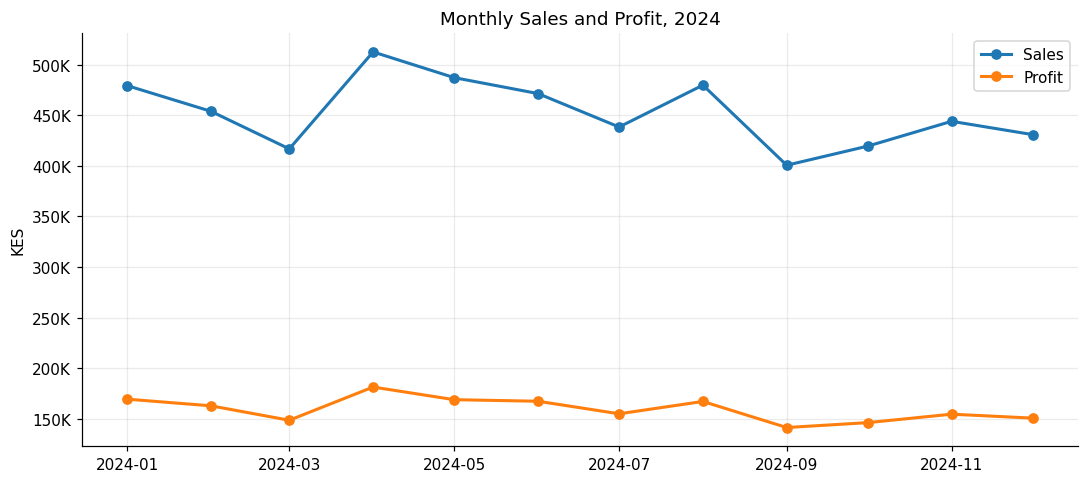

In [15]:
monthly = df.groupby('month')[['total_sales', 'profit']].sum()

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly.index, monthly['total_sales'], marker='o', lw=2, label='Sales')
ax.plot(monthly.index, monthly['profit'], marker='o', lw=2, label='Profit')
ax.yaxis.set_major_formatter(FuncFormatter(fmt))
ax.set_title('Monthly Sales and Profit, 2024'); ax.set_ylabel('KES'); ax.legend()
plt.tight_layout(); plt.savefig('1_monthly_trend.png'); plt.show()

### 2. Sales and profit by branch

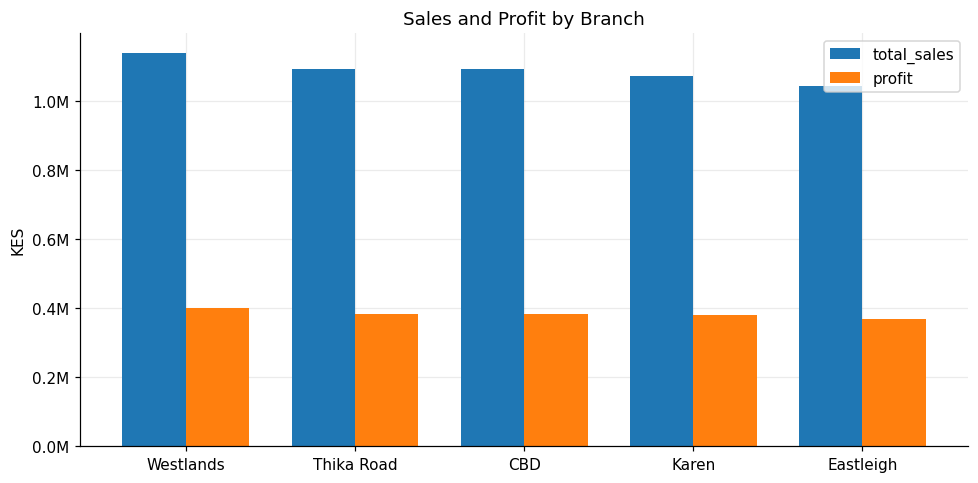

In [16]:
branch = df.groupby('branch', observed=True)[['total_sales', 'profit']].sum().sort_values('total_sales', ascending=False)

ax = branch.plot(kind='bar', figsize=(9, 4.5), width=0.75)
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
ax.set_title('Sales and Profit by Branch'); ax.set_ylabel('KES'); ax.set_xlabel('')
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig('2_branch_performance.png'); plt.show()

### 3. Profit by product category and margin

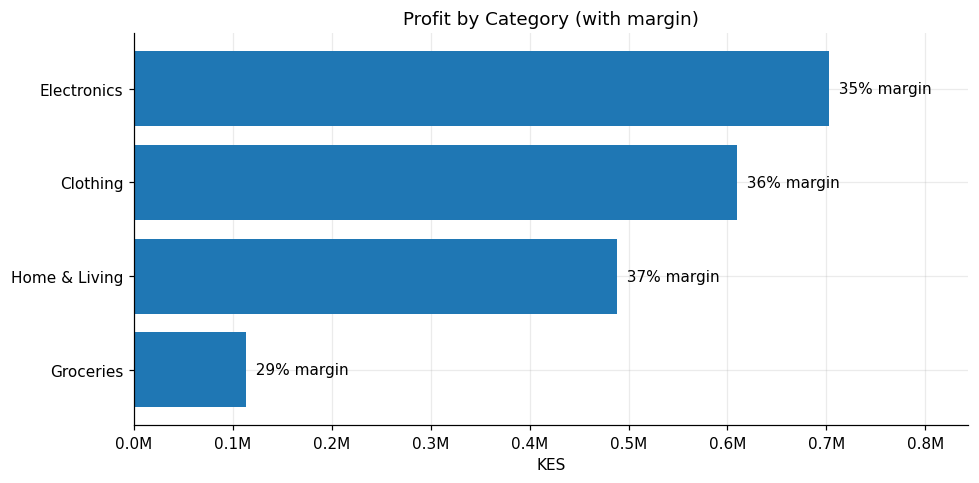

In [17]:
cat = df.groupby('product_category', observed=True).agg(profit=('profit', 'sum'), sales=('total_sales', 'sum'))
cat['margin_pct'] = cat['profit'] / cat['sales'] * 100
cat = cat.sort_values('profit')

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(cat.index, cat['profit'])
for b, m in zip(bars, cat['margin_pct']):
    ax.text(b.get_width(), b.get_y() + b.get_height()/2, f'  {m:.0f}% margin', va='center')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{x/1e6:.1f}M'))
ax.set_xlim(0, cat['profit'].max() * 1.2)
ax.set_title('Profit by Category (with margin)'); ax.set_xlabel('KES')
plt.tight_layout(); plt.savefig('3_category_profit.png'); plt.show()

### 4. Top products by profit

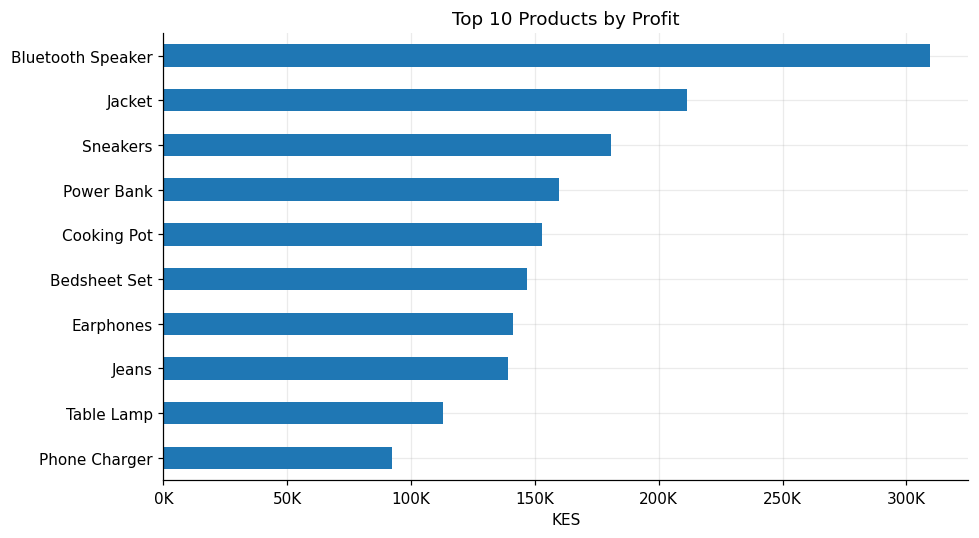

In [18]:
prod = df.groupby('product_name', observed=True)['profit'].sum().sort_values().tail(10)

ax = prod.plot(kind='barh', figsize=(9, 5))
ax.xaxis.set_major_formatter(FuncFormatter(fmt))
ax.set_title('Top 10 Products by Profit'); ax.set_xlabel('KES'); ax.set_ylabel('')
plt.tight_layout(); plt.savefig('4_top_products.png'); plt.show()

### 5. Payment methods

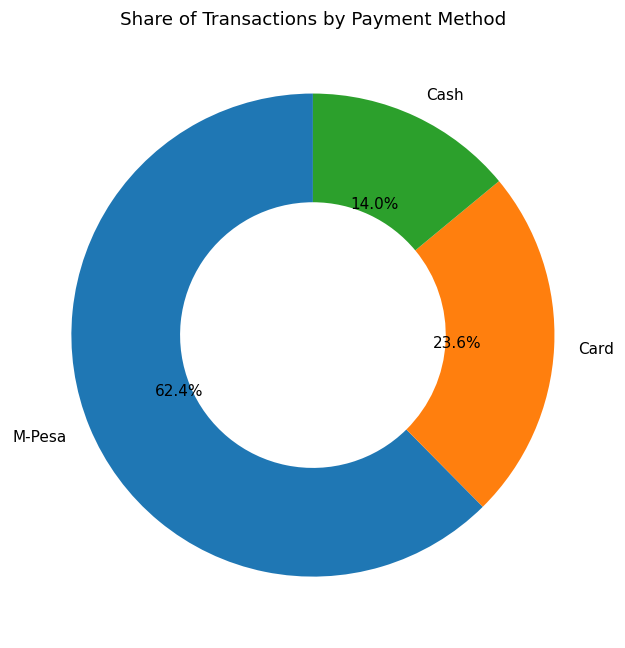

In [19]:
pay = df['payment_method'].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(pay, labels=pay.index, autopct='%1.1f%%', startangle=90, wedgeprops={'width': 0.45})
ax.set_title('Share of Transactions by Payment Method')
plt.tight_layout(); plt.savefig('5_payment_methods.png'); plt.show()

### 6. Customer satisfaction and return rate by branch

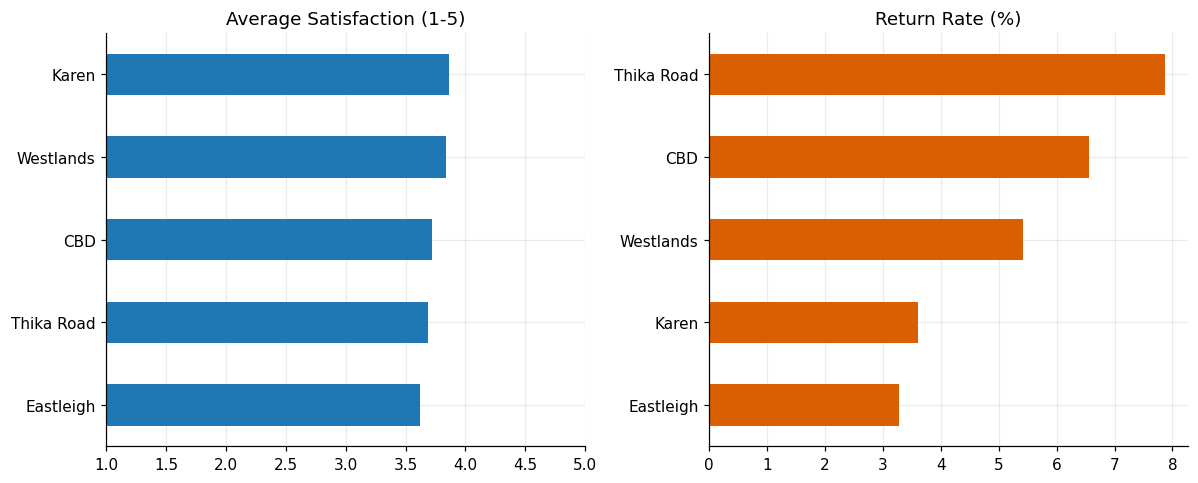

In [20]:
sat = df.groupby('branch', observed=True).agg(avg_satisfaction=('customer_satisfaction', 'mean'),
                                               return_rate=('returned', 'mean'))
sat['return_rate'] *= 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sat['avg_satisfaction'].sort_values().plot(kind='barh', ax=axes[0])
axes[0].set_xlim(1, 5); axes[0].set_title('Average Satisfaction (1-5)'); axes[0].set_ylabel('')
sat['return_rate'].sort_values().plot(kind='barh', ax=axes[1], color='#d95f02')
axes[1].set_title('Return Rate (%)'); axes[1].set_ylabel('')
plt.tight_layout(); plt.savefig('6_satisfaction_returns.png'); plt.show()

### 7. Sales heatmap: branch x month

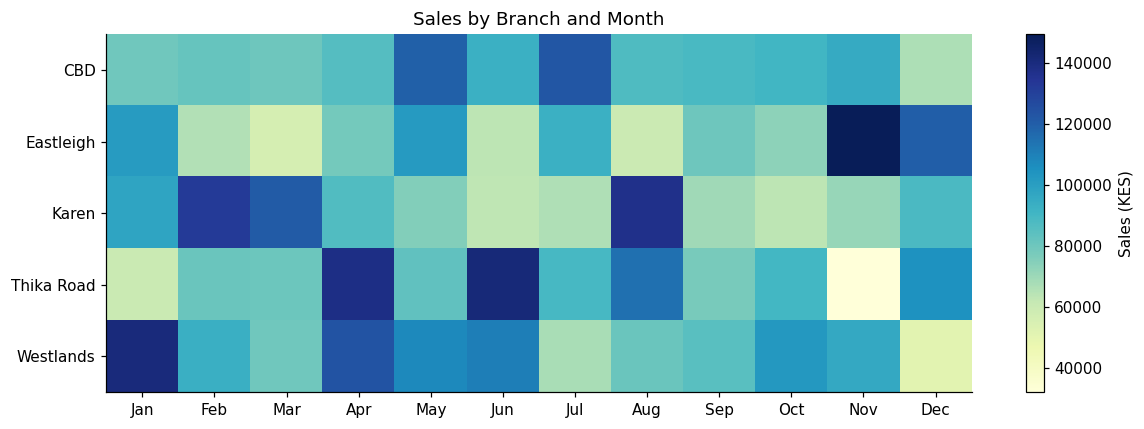

In [21]:
pivot = df.pivot_table(index='branch', columns=df['date'].dt.month, values='total_sales', aggfunc='sum', observed=True)

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(pivot, aspect='auto', cmap='YlGnBu')
ax.set_xticks(range(12)); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_yticks(range(len(pivot))); ax.set_yticklabels(pivot.index)
ax.grid(False); fig.colorbar(im, label='Sales (KES)')
ax.set_title('Sales by Branch and Month')
plt.tight_layout(); plt.savefig('7_heatmap.png'); plt.show()